# Formula 1 Podium Prediction — Milestone 1
**CSEN 903 Advanced Computer Lab — Team [40]**

**Goal:** predict, for each driver in each race, whether they finish on the podium (top 3),
using only information available after qualifying and before the race starts.

1. Setup & Data Loading
2. Table-by-Table Audit & Cleaning (EDA → cleaning → after-check for each table)
3. Cross-Table Checks & Cleaning (foreign keys, grain, era decisions, joins)
4. EDA on the Combined Data
5. Data-Engineering Questions
6. Feature Engineering & Selection
7. Train / Validation / Test Split
8. Modeling
9. Experiments
10. Explainability (XAI)
11. Inference Function

# 1. Setup & Data Loading
## 1.1 Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

np.random.seed(42)

## 1.2 Load the 14 raw tables
Each CSV is loaded into its own DataFrame. These raw tables are never modified; all cleaning is done on copies.

In [3]:
path = '..\\ACL_9th-F1\\F1\\'

circuits              = pd.read_csv(path + 'circuits.csv')
constructors          = pd.read_csv(path + 'constructors.csv')
constructor_results   = pd.read_csv(path + 'constructor_results.csv')
constructor_standings = pd.read_csv(path + 'constructor_standings.csv')
drivers               = pd.read_csv(path + 'drivers.csv')
driver_standings      = pd.read_csv(path + 'driver_standings.csv')
races                 = pd.read_csv(path + 'races.csv')
results               = pd.read_csv(path + 'results.csv')
qualifying            = pd.read_csv(path + 'qualifying.csv')
lap_times             = pd.read_csv(path + 'lap_times.csv')
pit_stops             = pd.read_csv(path + 'pit_stops.csv')
sprint_results        = pd.read_csv(path + 'sprint_results.csv')
seasons               = pd.read_csv(path + 'seasons.csv')
status                = pd.read_csv(path + 'status.csv')

## 1.3 Check table sizes
Shape = (rows, columns).

In [4]:

print("lap_times:", lap_times.shape)
print("pit_stops:", pit_stops.shape)
print("sprint_results:", sprint_results.shape)
print("seasons:", seasons.shape)
print("status:", status.shape)

lap_times: (589081, 6)
pit_stops: (11371, 7)
sprint_results: (360, 16)
seasons: (75, 2)
status: (139, 2)


**Observations (from the shapes above):**
- All 14 tables loaded. Sizes range from 75 rows (`seasons`) to 589,081 rows (`lap_times`).
- `results` has 26,759 rows while `qualifying` has only 10,494, so qualifying has far fewer records.

**To check in the EDA:**
- Which years `qualifying` covers, and why it has fewer rows than `results`.
- Whether `results` has exactly one row per driver per race (the brief's required grain).
- Which years the data covers (`seasons` has 75 rows; confirm the year range).

# 2. Table-by-Table Audit & Cleaning
Each table is inspected before any cleaning: structure, missing values, `\N` placeholders,
primary key validity, and anything unusual. Every observation is based on the output above it.

## 2.1 Races
One row = one race. This table gives each race's season, round and date, used for the time-based split
and for finding each race's previous race.
### 2.1.1 First look

In [5]:
races.head()

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N


In [6]:
races.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1125 entries, 0 to 1124
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   raceId       1125 non-null   int64 
 1   year         1125 non-null   int64 
 2   round        1125 non-null   int64 
 3   circuitId    1125 non-null   int64 
 4   name         1125 non-null   object
 5   date         1125 non-null   object
 6   time         1125 non-null   object
 7   url          1125 non-null   object
 8   fp1_date     1125 non-null   object
 9   fp1_time     1125 non-null   object
 10  fp2_date     1125 non-null   object
 11  fp2_time     1125 non-null   object
 12  fp3_date     1125 non-null   object
 13  fp3_time     1125 non-null   object
 14  quali_date   1125 non-null   object
 15  quali_time   1125 non-null   object
 16  sprint_date  1125 non-null   object
 17  sprint_time  1125 non-null   object
dtypes: int64(4), object(14)
memory usage: 158.3+ KB


In [7]:
races.isnull().sum()

raceId         0
year           0
round          0
circuitId      0
name           0
date           0
time           0
url            0
fp1_date       0
fp1_time       0
fp2_date       0
fp2_time       0
fp3_date       0
fp3_time       0
quali_date     0
quali_time     0
sprint_date    0
sprint_time    0
dtype: int64

In [8]:
(races == '\\N').sum()

raceId            0
year              0
round             0
circuitId         0
name              0
date              0
time            731
url               0
fp1_date       1035
fp1_time       1057
fp2_date       1035
fp2_time       1057
fp3_date       1053
fp3_time       1072
quali_date     1035
quali_time     1057
sprint_date    1107
sprint_time    1110
dtype: int64

### Number of races per season

In [9]:
races['year'].value_counts().sort_index()

year
1950     7
1951     8
1952     8
1953     9
1954     9
        ..
2020    17
2021    22
2022    22
2023    22
2024    24
Name: count, Length: 75, dtype: int64

In [10]:
print("raceId unique:", races['raceId'].is_unique)
print("raceId nulls:", races['raceId'].isnull().sum())

raceId unique: True
raceId nulls: 0


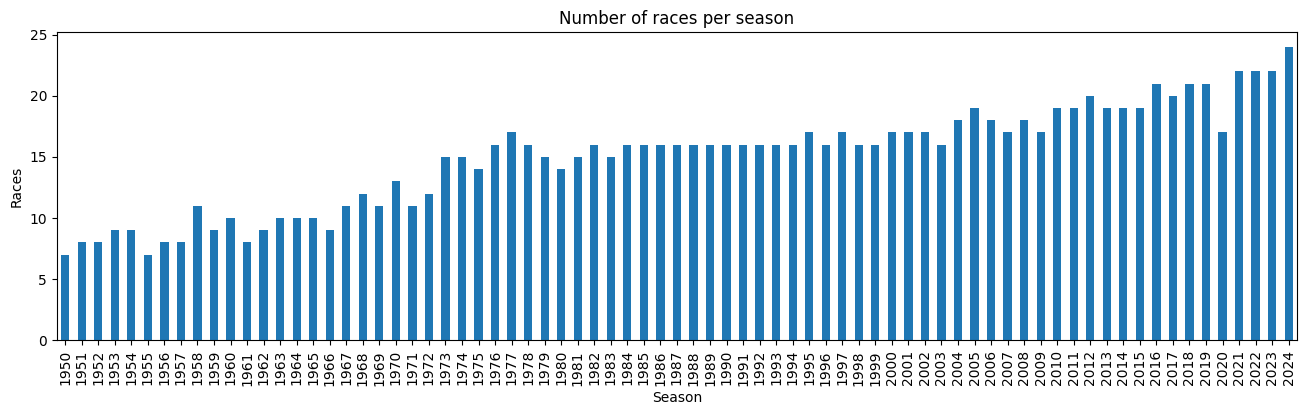

In [11]:
races['year'].value_counts().sort_index().plot(kind='bar', figsize=(16, 4))
plt.title('Number of races per season')
plt.xlabel('Season')
plt.ylabel('Races')
plt.show()

In [12]:
races.sort_values('date')[['raceId', 'year', 'round', 'name', 'date']].head()

,raceId,year,round,name,date
832,833,1950,1,British Grand Prix,1950-05-13
833,834,1950,2,Monaco Grand Prix,1950-05-21
834,835,1950,3,Indianapolis 500,1950-05-30
835,836,1950,4,Swiss Grand Prix,1950-06-04
836,837,1950,5,Belgian Grand Prix,1950-06-18


In [13]:
races_sorted = races.sort_values(['year', 'date'])
races_sorted['round_by_date'] = races_sorted.groupby('year').cumcount() + 1
(races_sorted['round'] != races_sorted['round_by_date']).sum()

np.int64(0)

In [14]:
races['date'].str.match(r'^\d{4}-\d{2}-\d{2}$').all()

np.True_

### Observations (races)

**Size and keys**
- 1,125 races and 18 columns (`races.info()`).
- `raceId` is unique and non-null, so it is a valid primary key (2.1.3).

**Missing values**
- `.isnull()` reports 0 missing values in every column, but the `\N` count shows many hidden ones:
  `time` (731 of 1,125), practice and qualifying session dates/times (1,035–1,072) and sprint
  dates/times (1,107–1,110). `.isnull()` alone does not detect this dataset's missing values.

**Coverage**
- 75 seasons, 1950–2024, with no year missing (`Length: 75`).
- Season length grew from 7 races (1950) to 24 (2024); 2020 had only 17 races (2.1.4 plot).

**Ordering**
- `raceId` is not in time order: the earliest race (1950 British GP, 13 May 1950) has `raceId` 833,
  while `raceId` 1 is the 2009 Australian GP. `raceId` therefore cannot be used to find a race's
  previous race.
- Within every season, `round` matches date order (0 mismatches), so `year` + `round` gives a
  reliable time order.
- All dates follow the `YYYY-MM-DD` format (check returned `True`), but they are stored as text
  (`object`) and must be converted to a date type.   ← keep only if cell 15 printed True

**Content**
- The Indianapolis 500 is listed as a championship race (round 3 of 1950). Whether to keep it is
  decided in Section 3, since it affects several tables.

### Cleaning
Based on the observations above:
- `\N` is replaced with NaN so pandas recognises missing values.
- `date` is converted from text to a date type.
- `name` is renamed to `race_name`, since `circuits` and `constructors` also have a `name` column,
  which would clash when tables are joined.
- Dropped columns:
  - `url`: Wikipedia link, no race information.
  - `time`, practice, qualifying and sprint date/time columns: when sessions took place, not their results;
    mostly `\N` (731–1,110 of 1,125).
All changes are made on a copy; the raw `races` table is unchanged.

In [15]:
races_clean = races.copy()
races_clean = races_clean.replace('\\N', np.nan)
races_clean['date'] = pd.to_datetime(races_clean['date'], format='%Y-%m-%d')
races_clean = races_clean.rename(columns={'name': 'race_name'})
races_clean = races_clean.drop(columns=['url', 'time',
                                        'fp1_date', 'fp1_time', 'fp2_date', 'fp2_time',
                                        'fp3_date', 'fp3_time', 'quali_date', 'quali_time',
                                        'sprint_date', 'sprint_time'])

### After cleaning

In [16]:
races_clean.head()

,raceId,year,round,circuitId,race_name,date
0,1,2009,1,1,Australian Grand Prix,2009-03-29
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05
2,3,2009,3,17,Chinese Grand Prix,2009-04-19
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26
4,5,2009,5,4,Spanish Grand Prix,2009-05-10


In [17]:
races_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1125 entries, 0 to 1124
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   raceId     1125 non-null   int64         
 1   year       1125 non-null   int64         
 2   round      1125 non-null   int64         
 3   circuitId  1125 non-null   int64         
 4   race_name  1125 non-null   object        
 5   date       1125 non-null   datetime64[ns]
dtypes: datetime64[ns](1), int64(4), object(1)
memory usage: 52.9+ KB


In [18]:
(races_clean == '\\N').sum().sum()

np.int64(0)

In [19]:
races_clean[['year', 'round']].describe()

,year,round
count,1125.000000,1125.000000
mean,1992.703111,8.579556
std,20.603848,5.159910
min,1950.000000,1.000000
25%,1977.000000,4.000000
50%,1994.000000,8.000000
75%,2011.000000,13.000000
max,2024.000000,24.000000


### Indianapolis 500 races
Identified here for the keep/exclude decision in Section 3.

In [20]:
indy_ids = races_clean[races_clean['race_name'] == 'Indianapolis 500']['raceId']
races_clean[races_clean['raceId'].isin(indy_ids)][['raceId', 'year', 'round', 'race_name']]

,raceId,year,round,race_name
747,748,1960,3,Indianapolis 500
756,757,1959,2,Indianapolis 500
767,768,1958,4,Indianapolis 500
777,778,1957,3,Indianapolis 500
785,786,1956,3,Indianapolis 500
793,794,1955,3,Indianapolis 500
799,800,1954,2,Indianapolis 500
808,809,1953,2,Indianapolis 500
817,818,1952,2,Indianapolis 500
825,826,1951,2,Indianapolis 500


### 2.1.10 Summary (races)

**Findings (EDA)**
- 1,125 races over 75 seasons (1950–2024); `raceId` is a valid primary key.
- Missing values are hidden as `\N` (not detected by `.isnull()`), concentrated in session schedule columns.
- `raceId` is not chronological; `year` + `round` gives the correct time order (verified: 0 mismatches with date order).
- Dates were stored as text, all in `YYYY-MM-DD` format.
- The Indianapolis 500 appears as a championship race 11 times, once per season from 1950 to 1960
  (verified in the data), matching the F1 background document.

**Cleaning applied**
- `\N` → NaN; `date` converted to datetime; `name` renamed to `race_name`.
- 12 columns dropped (URL and session schedule columns, mostly `\N`).
- Result: `races_clean` with 6 columns, 1,125 rows, no missing values, no `\N`, valid year/round ranges.

**Rules for the rest of the notebook**
- Races are always ordered by `year` + `round`, never by `raceId`.
- Use `races_clean` (not `races`) in all later joins; the race name column is `race_name`.

**Deferred to Section 3**
- Keep or exclude the Indianapolis 500 (its 11 `raceId`s are saved in `indy_ids`); this affects
  `results`, `qualifying` and other tables.
- Foreign key check: every `races.circuitId` must exist in `circuits.circuitId`.

## 2.2 Circuits 
this table provides the information about the circuits including name , location geographically and in country
### first look

In [21]:
circuits.head()

,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


In [22]:
circuits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB


In [23]:
circuits.describe()

,circuitId,lat,lng,alt
count,77.000000,77.000000,77.000000,77.000000
mean,39.883117,33.442925,1.076683,247.012987
std,23.001701,22.808866,65.516951,362.738469
min,1.000000,-37.849700,-118.189000,-7.000000
25%,20.000000,32.777400,-9.394170,18.000000
50%,40.000000,40.951700,3.930830,129.000000
75%,59.000000,46.958900,19.248600,332.000000
max,80.000000,57.265300,144.968000,2227.000000


In [24]:
(circuits == '\\N').sum()

circuitId     0
circuitRef    0
name          0
location      0
country       0
lat           0
lng           0
alt           0
url           0
dtype: int64

In [25]:
circuits.duplicated().sum()

np.int64(0)

### Notes 
in the following cell we were looking at the values of the countries and we noticed that there has been duplication (not explicitily) but the value usa and united stated that should have been considered same value 

In [26]:
circuits['country'].value_counts()

country
USA              11
France            7
Spain             6
Italy             4
Portugal          4
UK                4
Germany           3
Belgium           3
Canada            3
Japan             3
Australia         2
Austria           2
Brazil            2
South Africa      2
Malaysia          1
Bahrain           1
Hungary           1
Turkey            1
Monaco            1
United States     1
China             1
Singapore         1
Argentina         1
Mexico            1
Korea             1
Netherlands       1
UAE               1
Sweden            1
Morocco           1
Switzerland       1
India             1
Russia            1
Azerbaijan        1
Saudi Arabia      1
Qatar             1
Name: count, dtype: int64

In [27]:
print("circuitId unique:", circuits['circuitId'].is_unique)
print("circuitId nulls:", circuits['circuitId'].isnull().sum())

circuitId unique: True
circuitId nulls: 0


**Observations (circuits):**
- 77 circuits, no missing values and no `\N` sentinels.
- `circuitId` is unique and non-null, so it is a valid primary key (IDs go up to 80, so some numbers are unused).
- `alt` minimum is -7 m: a circuit below sea level, a real value rather than an error.
- **Inconsistent category:** the US appears as both `USA` (11) and `United States` (1).
  This must be standardised in cleaning, otherwise Question 2 (home races) would treat them as different countries.
- Columns we will use: `circuitId` (join key), `country` (Question 2).
- Columns that are irrelevant:CircuitRef, Name and url
- Other columns **may** be used in feature engineering as pasr races info.
- There are now row, circuitId,circuitRef or name Duplicates.

### Cleaning circuits table 
1. Fix duplicated USA - United States
2. Drop Unwanted Column in Circuits table

In [28]:
# fix duplication cell 
circuits_clean = circuits.copy()
circuits_clean['country'] = circuits_clean['country'].replace({'United States': 'USA'})

In [29]:
circuits_clean['country'].value_counts()

country
USA             12
France           7
Spain            6
Portugal         4
Italy            4
UK               4
Belgium          3
Canada           3
Germany          3
Japan            3
Austria          2
Australia        2
South Africa     2
Brazil           2
Malaysia         1
Turkey           1
Monaco           1
Bahrain          1
China            1
Singapore        1
Hungary          1
Argentina        1
Mexico           1
Korea            1
Netherlands      1
UAE              1
Sweden           1
Morocco          1
Switzerland      1
India            1
Russia           1
Azerbaijan       1
Saudi Arabia     1
Qatar            1
Name: count, dtype: int64

### Analysis of the coloumns 
1. url --> cannot be used in either training nor in data analysis because it doesnot hold information (the url string itself )
2. circuit ref , circuit name , location and country --> cannot be used in training as they are strings but would be useful in answering the data analysis questions
3. Rest of the coloumns --> numerical coloumns that could be used in the training but we refrain from dropping now as to see their coleration 

In [30]:
circuits_clean.drop(columns=['url',], inplace=True)

In [31]:
circuits_clean.head()

,circuitId,circuitRef,name,location,country,lat,lng,alt
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130


## 2.3 Constructor_results 
this table is mainly about constructors and their perfromances respectively in race (including points , status and race itself 
### Taking a look

In [32]:
constructor_results.head()

,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,\N
1,2,18,2,8.0,\N
2,3,18,3,9.0,\N
3,4,18,4,5.0,\N
4,5,18,5,2.0,\N


In [33]:
constructor_results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                12625 non-null  object 
dtypes: float64(1), int64(3), object(1)
memory usage: 493.3+ KB


In [34]:
constructor_results.isnull().sum()

constructorResultsId    0
raceId                  0
constructorId           0
points                  0
status                  0
dtype: int64

In [35]:
(constructor_results == '\\N').sum()

constructorResultsId        0
raceId                      0
constructorId               0
points                      0
status                  12608
dtype: int64

### Notes
we notice by running the below 2 cells that there are only **17 values of D** in the status column and we research that these were the year Mclaren was disqualified from results but the races points were still documented so we will reject the disqualification matter and deal with the actual results and will later change the positions from E to the valid position

- also we noticed that all of the constructors here are not classified meaning they are not on podium 

In [36]:
constructor_results['status'].value_counts()

status
\N    12608
D        17
Name: count, dtype: int64

In [37]:
constructor_results[constructor_results['status'] != '\\N']

,constructorResultsId,raceId,constructorId,points,status
185,186,36,1,14.0,D
195,196,37,1,18.0,D
207,208,38,1,12.0,D
218,219,39,1,14.0,D
228,229,40,1,18.0,D
239,240,41,1,12.0,D
250,251,42,1,18.0,D
262,263,43,1,8.0,D
273,274,44,1,14.0,D
283,284,45,1,10.0,D


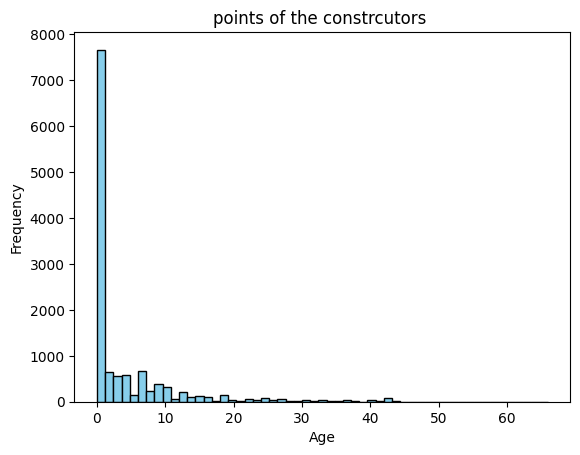

In [38]:
import matplotlib.pyplot as plt

# Plot using matplotlib by passing the dataframe column
plt.hist(constructor_results['points'],bins=55, color='skyblue', edgecolor='black')

plt.title('points of the constrcutors ')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()


In [39]:
constructor_results['points'].value_counts()

points
0.0     6985
1.0      680
2.0      643
4.0      586
6.0      577
        ... 
56.0       1
47.0       1
49.0       1
54.0       1
55.0       1
Name: count, Length: 61, dtype: int64

### Notes 
a lot of constrcutors (more than 6985 one ) got zero points on race ( because any one whos position from 11 to 20 got 0 points )
### Clean up 
1. changing /n values 
2. renaming colomn points

In [40]:
# Matches any string that contains a newline character anywhere inside it
constructor_results['status'] = constructor_results['status'].replace('\\N', np.nan)

In [41]:
constructor_results = constructor_results.rename(columns={'points': 'race_specific_contsructor_points'})

In [42]:
constructor_results.head()

,constructorResultsId,raceId,constructorId,race_specific_contsructor_points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN


## 2.4 Constructor standings 
this table also is centered around the constructors . it holds information about the cummlative points (included the race) of each constructor and race and their position 
### take a look

In [43]:
constructor_standings.head()

,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1
1,2,18,2,8.0,3,3,0
2,3,18,3,9.0,2,2,0
3,4,18,4,5.0,4,4,0
4,5,18,5,2.0,5,5,0


In [44]:
constructor_standings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13391 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   constructorStandingsId  13391 non-null  int64  
 1   raceId                  13391 non-null  int64  
 2   constructorId           13391 non-null  int64  
 3   points                  13391 non-null  float64
 4   position                13391 non-null  int64  
 5   positionText            13391 non-null  object 
 6   wins                    13391 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 732.4+ KB


In [45]:
constructor_standings.describe()

,constructorStandingsId,raceId,constructorId,points,position,wins
count,13391.000000,13391.000000,13391.000000,13391.000000,13391.000000,13391.000000
mean,16982.110821,535.399821,49.603390,37.178515,7.226047,0.697409
std,8868.446172,307.705928,61.213953,84.346048,4.355923,1.879569
min,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000
25%,8883.500000,302.000000,6.000000,0.000000,4.000000,0.000000
50%,20634.000000,508.000000,25.000000,7.000000,7.000000,0.000000
75%,25047.500000,740.000000,58.000000,33.000000,10.000000,0.000000
max,28982.000000,1144.000000,215.000000,860.000000,22.000000,21.000000


In [46]:
constructor_standings.isnull().sum()

constructorStandingsId    0
raceId                    0
constructorId             0
points                    0
position                  0
positionText              0
wins                      0
dtype: int64

In [47]:
(constructor_standings == '\\N').sum()

constructorStandingsId    0
raceId                    0
constructorId             0
points                    0
position                  0
positionText              0
wins                      0
dtype: int64

### Notes 
- no null values of \n in this table 
- in the next cell we looked at position text and we saw only one **E** which means excluded (we have to delete those rows later)


In [48]:
constructor_standings['positionText'].value_counts()


positionText
1     1061
3     1061
2     1061
4     1060
5     1060
6     1060
7     1056
8     1044
9     1030
10     999
11     706
12     497
13     389
14     333
15     300
16     227
17     179
18     124
19      94
20      29
E       17
21       3
22       1
Name: count, dtype: int64

### Notes 
in the following cell we also checked for wether in the same race they have duplicated on same position which they not appear to be 

In [49]:
duplicate_rows = constructor_standings[constructor_standings.duplicated(subset=['raceId', 'position'], keep=False)]
duplicate_rows

,constructorStandingsId,raceId,constructorId,points,position,positionText,wins


### Data cleaning 
- renaming the follwoing coloumns { points , position , positionText, wins}
- position text would not be used in training but it would be useful in extractign data and data analysis 



In [50]:
constructor_standings = constructor_standings.rename(columns={"points": "points_cumm_raceIncl","position":"team_position_soFar_inConstrChamp","positionText":"same_as_team_postion_but_with_E_for_2007_crisis","wins":"constructor_wins"})

In [51]:
constructor_standings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13391 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   constructorStandingsId                           13391 non-null  int64  
 1   raceId                                           13391 non-null  int64  
 2   constructorId                                    13391 non-null  int64  
 3   points_cumm_raceIncl                             13391 non-null  float64
 4   team_position_soFar_inConstrChamp                13391 non-null  int64  
 5   same_as_team_postion_but_with_E_for_2007_crisis  13391 non-null  object 
 6   constructor_wins                                 13391 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 732.4+ KB


## 2.5 Constructors 
this tables introduces the comstructors and their nationalities 
### Take a look

In [52]:
constructors.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   constructorId   212 non-null    int64 
 1   constructorRef  212 non-null    object
 2   name            212 non-null    object
 3   nationality     212 non-null    object
 4   url             212 non-null    object
dtypes: int64(1), object(4)
memory usage: 8.4+ KB


In [53]:
(constructors == '\\N').sum()

constructorId     0
constructorRef    0
name              0
nationality       0
url               0
dtype: int64

In [54]:
constructors['nationality'].value_counts()

nationality
British          86
American         39
Italian          30
French           13
German           10
Japanese          5
Swiss             5
Dutch             3
South African     3
Russian           2
Malaysian         2
Canadian          2
Indian            1
Austrian          1
Hong Kong         1
Irish             1
Mexican           1
Brazilian         1
New Zealander     1
Australian        1
Rhodesian         1
Belgian           1
East German       1
Spanish           1
Name: count, dtype: int64

In [55]:
print("constructorId unique:", constructors['constructorId'].is_unique)
print("constructorId nulls:", constructors['constructorId'].isnull().sum())

constructorId unique: True
constructorId nulls: 0


In [56]:
constructors[constructors['name'].duplicated(keep=False)]

,constructorId,constructorRef,name,nationality,url


### Notes 
- no constructors are duplicated 
- nationalities is duplicated in a sense which is east german and germany due to the split that happened to them between 1949 and 1990
- **So we notice from running the cell below that different constructors can have same nationality so we will leave this column as it means it may be that some nationalities perform better as for constructors**

In [57]:
constructors[constructors['nationality']=='British']

,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
15,16,bar,BAR,British,http://en.wikipedia.org/wiki/British_American_...
18,19,jaguar,Jaguar,British,http://en.wikipedia.org/wiki/Jaguar_Racing
20,21,arrows,Arrows,British,http://en.wikipedia.org/wiki/Arrows_Grand_Prix...
...,...,...,...,...,...
200,203,shadow-matra,Shadow-Matra,British,http://en.wikipedia.org/wiki/Shadow_Racing_Cars
201,204,brabham-alfa_romeo,Brabham-Alfa Romeo,British,http://en.wikipedia.org/wiki/Brabham
205,208,lotus_f1,Lotus F1,British,http://en.wikipedia.org/wiki/Lotus_F1
206,209,manor,Manor Marussia,British,http://en.wikipedia.org/wiki/Manor_Motorsport


### cleaning and observations about the coloumns
#### oberservation 
- url --> would be dropped immediatly
- constructorRef,name and nationality --> wouldnt be used in training as they are objects but would be useful in data analysis
- would say that about the whole table
#### Cleaning 
- renaming {nationality}
- changing east german to german in order to unify 

In [58]:
constructors = constructors.rename(columns={"nationality": "constructor_nationality"})

In [59]:
constructors['constructor_nationality'] = constructors['constructor_nationality'].replace({'East German': 'German'})

In [60]:
constructors['constructor_nationality'].value_counts()

constructor_nationality
British          86
American         39
Italian          30
French           13
German           11
Swiss             5
Japanese          5
South African     3
Dutch             3
Russian           2
Malaysian         2
Canadian          2
Austrian          1
Indian            1
Irish             1
Mexican           1
Brazilian         1
Hong Kong         1
Australian        1
New Zealander     1
Rhodesian         1
Belgian           1
Spanish           1
Name: count, dtype: int64

In [61]:
constructors.drop(columns=['url','constructorRef'],inplace=True,)
constructors.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 3 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   constructorId            212 non-null    int64 
 1   name                     212 non-null    object
 2   constructor_nationality  212 non-null    object
dtypes: int64(1), object(2)
memory usage: 5.1+ KB


## 2.6 Driver_standings 
this tables shows the perfromance of the driver in races across the years with their resepctive accumplated points including the race and their psoition after the race 
### take a look

In [62]:
driver_standings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34863 entries, 0 to 34862
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   driverStandingsId  34863 non-null  int64  
 1   raceId             34863 non-null  int64  
 2   driverId           34863 non-null  int64  
 3   points             34863 non-null  float64
 4   position           34863 non-null  int64  
 5   positionText       34863 non-null  object 
 6   wins               34863 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 1.9+ MB


In [63]:
driver_standings['positionText'].value_counts()

positionText
1      1125
2      1125
3      1125
4      1125
5      1125
       ... 
104       2
D         1
108       1
107       1
106       1
Name: count, Length: 109, dtype: int64

In [64]:
(driver_standings == '\\N').sum()

driverStandingsId    0
raceId               0
driverId             0
points               0
position             0
positionText         0
wins                 0
dtype: int64

### Notes 
- We observe that there is one row with position text = d dueto the incident of michael schumacher . this will be resolved later
- also there is no \n values in this table 

In [65]:
driver_standings[driver_standings['positionText'] == 'D']

,driverStandingsId,raceId,driverId,points,position,positionText,wins
4375,11031,223,30,78.0,26,D,5


### cleaning and observations 
#### observations 
- position Text would be used as data analysis
#### cleaning 
- renaming the following coloumns {points , position, positionText, wins} for easier intreptations 


In [66]:
driver_standings = driver_standings.rename(columns={
    'points': 'driver_points_cumm',
    'position': 'driver_position1-in-rankings-of-season-so-far',
    'wins':'driver_wins_cumm',
    'positionText':'driver_position_sofar_text'
})


In [67]:
driver_standings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34863 entries, 0 to 34862
Data columns (total 7 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   driverStandingsId                              34863 non-null  int64  
 1   raceId                                         34863 non-null  int64  
 2   driverId                                       34863 non-null  int64  
 3   driver_points_cumm                             34863 non-null  float64
 4   driver_position1-in-rankings-of-season-so-far  34863 non-null  int64  
 5   driver_position_sofar_text                     34863 non-null  object 
 6   driver_wins_cumm                               34863 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 1.9+ MB


## 2.7 Drivers 
this tables witholds information about teh drivers and their nationalties and Date of birth 
#### take a look

In [68]:
drivers.head()

,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,\N,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,\N,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen


In [69]:
drivers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   driverId     861 non-null    int64 
 1   driverRef    861 non-null    object
 2   number       861 non-null    object
 3   code         861 non-null    object
 4   forename     861 non-null    object
 5   surname      861 non-null    object
 6   dob          861 non-null    object
 7   nationality  861 non-null    object
 8   url          861 non-null    object
dtypes: int64(1), object(8)
memory usage: 60.7+ KB


In [70]:
drivers.duplicated().sum()
#nothing is duplicated
has_duplicates = drivers['driverId'].duplicated().any()
print(f"Are there duplicates? {has_duplicates}")

Are there duplicates? False


In [71]:
(drivers == '\\N').sum()

driverId         0
driverRef        0
number         802
code           757
forename         0
surname          0
dob              0
nationality      0
url              0
dtype: int64

### Cleaning and observations 
#### Observations 
- url --> be droppped ( same reason as prev)
- number --> would be dropped as 802 out of 861 of the coloumn is \n
- code  --> would be dropped as 757 out of 861 of the coloumn is \n
- other object (surname , forname & ref ) help in recognizing the driver not the training
- date of birth would be changed numerical in order to use to for feature coleration
#### cleaning 
- dropping coloumn { url,code , number ,driverref}
- merging forename and surname (for data anaylsis purposes )
- chaning dob into numerical format
- renaming the nationality 

In [72]:
drivers = drivers.rename(columns={
    'nationality': 'drivers_nationality',
    
})

In [73]:
drivers.drop(columns=['number','code','url','driverRef'], inplace=True)

In [74]:
# Merge name columns with a space between them
drivers['driver_name'] = drivers['forename'] + ' ' + drivers['surname']

In [75]:
drivers.drop(columns=['forename','surname'], inplace=True)

In [76]:
drivers.head()

,driverId,dob,drivers_nationality,driver_name
0,1,1985-01-07,British,Lewis Hamilton
1,2,1977-05-10,German,Nick Heidfeld
2,3,1985-06-27,German,Nico Rosberg
3,4,1981-07-29,Spanish,Fernando Alonso
4,5,1981-10-19,Finnish,Heikki Kovalainen


In [77]:
from datetime import datetime
today = datetime.now()
drivers['dob'] = pd.to_datetime(drivers['dob'])
drivers['age'] = ((today - drivers['dob']).dt.days / 365.25).astype(int)

In [78]:
drivers.info()
drivers.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   driverId             861 non-null    int64         
 1   dob                  861 non-null    datetime64[ns]
 2   drivers_nationality  861 non-null    object        
 3   driver_name          861 non-null    object        
 4   age                  861 non-null    int64         
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 33.8+ KB


,driverId,dob,drivers_nationality,driver_name,age
0,1,1985-01-07,British,Lewis Hamilton,41
1,2,1977-05-10,German,Nick Heidfeld,49
2,3,1985-06-27,German,Nico Rosberg,41
3,4,1981-07-29,Spanish,Fernando Alonso,45
4,5,1981-10-19,Finnish,Heikki Kovalainen,44


In [79]:
drivers.drop(columns='dob',inplace=True)

In [80]:
drivers.head()

,driverId,drivers_nationality,driver_name,age
0,1,British,Lewis Hamilton,41
1,2,German,Nick Heidfeld,49
2,3,German,Nico Rosberg,41
3,4,Spanish,Fernando Alonso,45
4,5,Finnish,Heikki Kovalainen,44


## 2.8 Lap times
this table have analysis of drivers for each lap they have done per race 
### take a look


In [81]:
lap_times.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   raceId        589081 non-null  int64 
 1   driverId      589081 non-null  int64 
 2   lap           589081 non-null  int64 
 3   position      589081 non-null  int64 
 4   time          589081 non-null  object
 5   milliseconds  589081 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 27.0+ MB


In [82]:
(lap_times == '\\N').sum()
lap_times.isnull().sum()

raceId          0
driverId        0
lap             0
position        0
time            0
milliseconds    0
dtype: int64

In [83]:
duplicate_rows = lap_times[lap_times.duplicated(subset=['raceId', 'driverId','lap'], keep=False)]
duplicate_rows

,raceId,driverId,lap,position,time,milliseconds


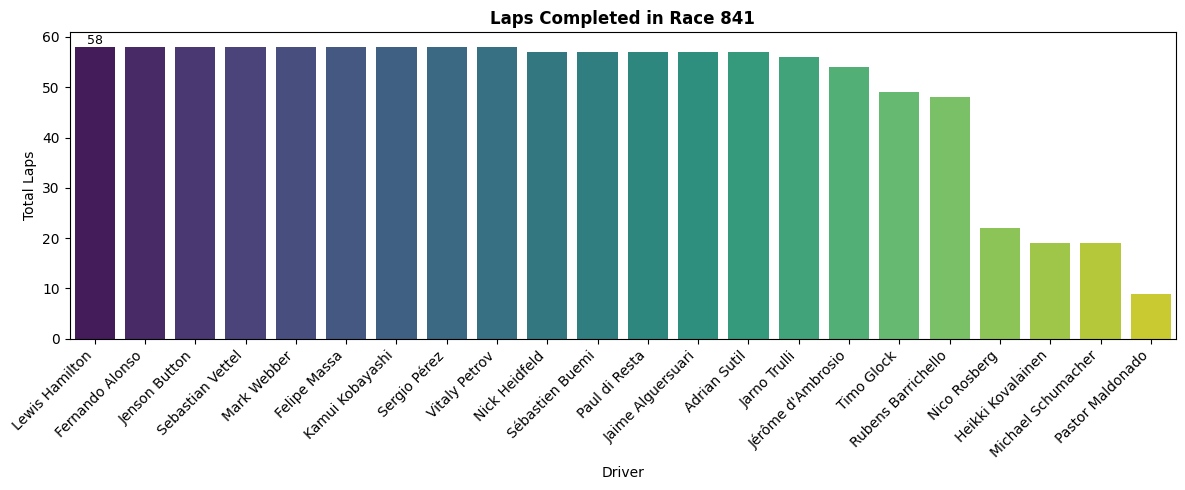

In [84]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Count the laps (rows) per driver in your target race (e.g., raceId 841)
target_race_id = 841
race_laps = lap_times[lap_times["raceId"] == target_race_id]
lap_counts = (
    race_laps.groupby("driverId").size().reset_index(name="laps_completed")
)

# 2. Merge with your clean drivers table to get their names
final_df = pd.merge(lap_counts, drivers, on="driverId", how="left")
final_df = final_df.sort_values(by="laps_completed", ascending=False)

# 3. Create a clean, simple bar plot
plt.figure(figsize=(12, 5))

# Fixed the deprecation warning by adding hue= and legend=False
ax = sns.barplot(
    data=final_df,
    x="driver_name",
    y="laps_completed",
    hue="driver_name",
    legend=False,
    palette="viridis",
)

# 4. Add the labels on top of the bars (Fixed the list error here)
ax.bar_label(ax.containers[0], fontsize=9)

# 5. Clean layout adjustments
plt.title(f"Laps Completed in Race {target_race_id}", fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Driver")
plt.ylabel("Total Laps")
plt.tight_layout()

plt.show()


###  Key Observations: Race Lap Completion Profile (Race ID: 841)

> **Context:** This analysis isolates a single Grand Prix event from the `lap_times` table to evaluate driver reliability and completion rates. 

* **The Lead Pack Plateau:** The dominant, flat horizontal plateau on the left side of our visualization represents the drivers who completed the maximum race distance of **58 laps**. This confirms a clean run without race-ending incidents or terminal mechanical failures.
* **Isolating DNFs (Did Not Finish):** The stepping-down distribution on the right side of the chart visually identifies mid-race retirements. 
* **Reliability Metrics:** Drivers with drastically shorter bars represent early-race casualties (e.g., first-lap collisions), while those closer to the 58-lap threshold indicate late-stage heartbreaks, such as mechanical failures or retirements in the closing stages of the Grand Prix.

---

#### 🛠️ Data Architecture Note
* **`lap_times` Integrity:** Verified. The counting script aggregates unique row entries matching the compound signature `['raceId', 'driverId']`. 
* **Data Completeness:** The maximum value matches the total official race lap count, ensuring no overlapping lap time anomalies exist in this segment of the database.


### Cleaning and Observations
#### Observations 
- time would be dropped as it is object and there is its numerical correspondant
- every other feature would be used later in feature engineering sections
#### Cleaning 
- drop time
- rename {position,milliseconds}

In [85]:
lap_times['position'].value_counts()

position
1     33196
2     33196
3     33189
4     33173
5     33142
6     33094
7     32937
8     32860
9     32712
10    32471
11    32093
12    31549
13    30772
14    29832
15    28611
16    26687
17    24303
18    20431
19    15684
20    10114
21     4655
22     2701
23     1116
24      563
Name: count, dtype: int64

In [86]:
lap_times.drop(columns=['time'], inplace=True)

In [87]:
lap_times = lap_times.rename(columns={
    'position': 'position_in_lap',
    'milliseconds': 'milliseconds_per_lap'
})


In [88]:
lap_times.head()

,raceId,driverId,lap,position_in_lap,milliseconds_per_lap
0,841,20,1,1,98109
1,841,20,2,1,93006
2,841,20,3,1,92713
3,841,20,4,1,92803
4,841,20,5,1,92342


## 2.9 pit_stops 
this table provides information  when cars entered the pits, how long they stayed, and how it affected their race strategy


In [89]:
pit_stops.head()

,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842


In [90]:
pit_stops.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   raceId        11371 non-null  int64 
 1   driverId      11371 non-null  int64 
 2   stop          11371 non-null  int64 
 3   lap           11371 non-null  int64 
 4   time          11371 non-null  object
 5   duration      11371 non-null  object
 6   milliseconds  11371 non-null  int64 
dtypes: int64(5), object(2)
memory usage: 622.0+ KB


--- Strategy Frequency Distribution ---
 Strategy (Num of Stops)  Driver Count
                       1             4
                       2            12
                       3             3


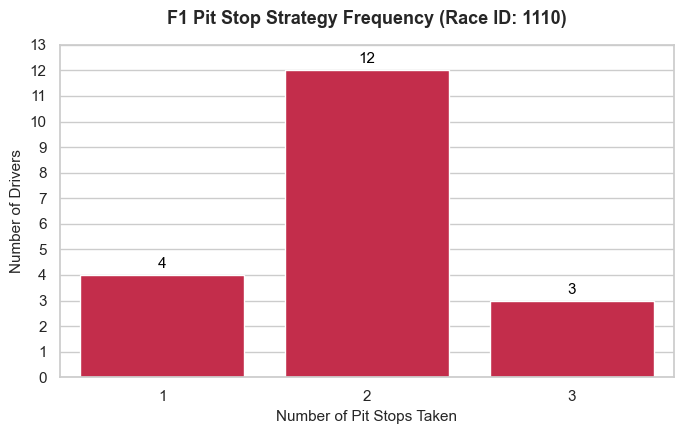

In [91]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df_pit_stops = pd.DataFrame(pit_stops) is already loaded

# 1. AGGREGATE PER RACE: Include 'raceId' in the groupby
# This finds the maximum pit stop number for each driver in *each separate race*
df_pit_stops = pd.DataFrame(pit_stops)
driver_race_totals = df_pit_stops.groupby(["raceId", "driverId"])["stop"].max().reset_index()
driver_race_totals.rename(columns={"stop": "Total_Pit_Stops"}, inplace=True)

# -------------------------------------------------------------
# OPTION A: Filter to look at ONE specific race (e.g., raceId 1110)
# This fixes your data so numbers like 51, 52, or 70 drop down to standard 1, 2, or 3 stops.
target_race_id = 1110  
single_race_df = driver_race_totals[driver_race_totals["raceId"] == target_race_id]

# Calculate the frequency bucket for just this one race
frequency_df = single_race_df["Total_Pit_Stops"].value_counts().reset_index()
frequency_df.columns = ["Strategy (Num of Stops)", "Driver Count"]
frequency_df.sort_values(by="Strategy (Num of Stops)", inplace=True)
# -------------------------------------------------------------

# -------------------------------------------------------------
# OPTION B: Un-comment the 3 lines below if you want an overall historical average 
# of how frequent 1, 2, or 3 stop strategies are across ALL individual races combined:
# frequency_df = driver_race_totals["Total_Pit_Stops"].value_counts().reset_index()
# frequency_df.columns = ["Strategy (Num of Stops)", "Driver Count"]
# frequency_df.sort_values(by="Strategy (Num of Stops)", inplace=True)
# -------------------------------------------------------------

print("--- Strategy Frequency Distribution ---")
print(frequency_df.to_string(index=False))

# 2. VISUALIZE: Plot the strategy frequencies 
plt.figure(figsize=(7, 4.5))
sns.set_theme(style="whitegrid")

ax = sns.barplot(x="Strategy (Num of Stops)", y="Driver Count", data=frequency_df, color="crimson")

# Formatting 
plt.title(f"F1 Pit Stop Strategy Frequency (Race ID: {target_race_id})", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Number of Pit Stops Taken", fontsize=11)
plt.ylabel("Number of Drivers", fontsize=11)
plt.yticks(range(0, frequency_df["Driver Count"].max() + 2))

# Add value labels over the bars
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{int(p.get_height())}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='baseline', fontsize=11, color='black', 
                    xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()


--- Total Pit Stops Per Driver ---

--- Strategy Frequency Distribution ---


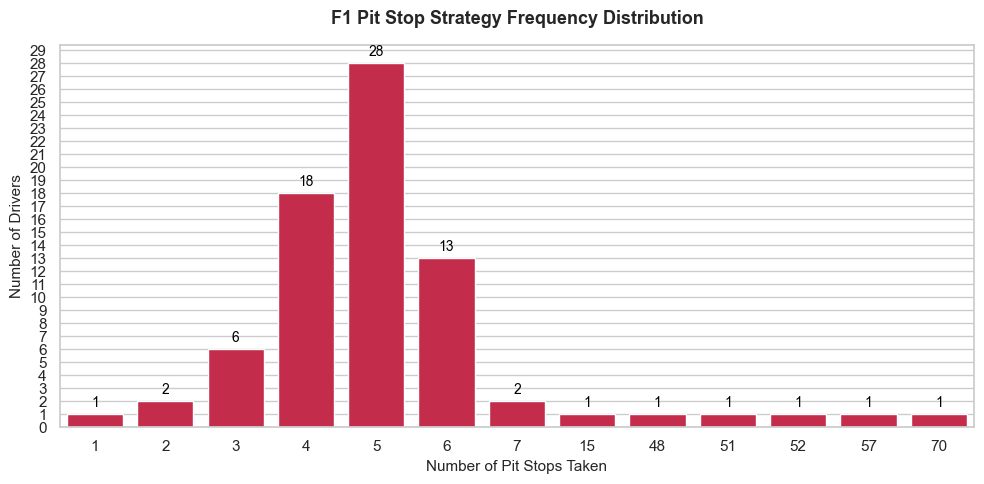

In [92]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df_pit_stops = pd.DataFrame(pit_stops) is already loaded

# 2. AGGREGATE: Group by driver to extract the maximum value in the 'stop' column
driver_totals = df_pit_stops.groupby(["driverId"])["stop"].max().reset_index()

# FIX: Changed "stops" to "stop" to match your actual column name
driver_totals.rename(columns={"stop": "Total_Pit_Stops"}, inplace=True)

print("--- Total Pit Stops Per Driver ---")
#print(driver_totals.to_string(index=False))

# 3. FREQUENCY DISTRIBUTION: Count how many drivers fall into each strategy bucket
frequency_df = driver_totals["Total_Pit_Stops"].value_counts().reset_index()
frequency_df.columns = ["Strategy (Num of Stops)", "Driver Count"]
frequency_df.sort_values(by="Strategy (Num of Stops)", inplace=True)

print("\n--- Strategy Frequency Distribution ---")
#print(frequency_df.to_string(index=False))

# 4. VISUALIZE: Plot the strategy frequencies 
plt.figure(figsize=(10, 5)) # Slightly wider layout to accommodate historical data ranges
sns.set_theme(style="whitegrid")

# Create a bar plot of the aggregated frequencies
ax = sns.barplot(x="Strategy (Num of Stops)", y="Driver Count", data=frequency_df, color="crimson")

# Formatting 
plt.title("F1 Pit Stop Strategy Frequency Distribution", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Number of Pit Stops Taken", fontsize=11)
plt.ylabel("Number of Drivers", fontsize=11)
plt.yticks(range(0, frequency_df["Driver Count"].max() + 2))

# Add value labels over the bars
for p in ax.patches:
    if p.get_height() > 0: # Only label bars that have data
        ax.annotate(f'{int(p.get_height())}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='baseline', fontsize=10, color='black', 
                    xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()


### Cleaning and Observations 
#### observations 
-  time --> would be dropped as it indicated the time that the pitstop
#### cleaning 
-  duration --> needs to be changed into numerical
-  renaming coloumns { lap , milliseconds }


In [93]:
pit_stops.drop(columns=['time'], inplace=True)

In [94]:
pit_stops = pit_stops.rename(columns={
    'lap': 'pitstop_lap',
    'milliseconds': 'pitstop_timetaken_in_ml'
})


In [95]:


# 1. Define a function to convert "MM:SS.fff" or "SS.fff" string formats into total seconds
def time_to_seconds(val):
    if pd.isna(val):
        return None
    
    val = str(val).strip()
    
    # If there is a colon (MM:SS.fff), split into minutes and seconds
    if ":" in val:
        try:
            minutes, seconds = val.split(":")
            return (float(minutes) * 60) + float(seconds)
        except ValueError:
            return None # Handles any unexpected bad string formatting
            
    # If it's already just seconds (SS.fff), convert directly to float
    try:
        return float(val)
    except ValueError:
        return None

# 2. Apply the custom function to your duration column
pit_stops['duration'] = pit_stops['duration'].apply(time_to_seconds)

# 3. Ensure the final column is strictly recognized as a numerical float type by pandas
pit_stops['duration'] = pd.to_numeric(pit_stops['duration'], errors='coerce')

# Check your results!
print(pit_stops['duration'].head())


0    26.898
1    25.021
2    23.426
3    23.251
4    23.842
Name: duration, dtype: float64


In [96]:
(pit_stops == '\\N').sum()

raceId                     0
driverId                   0
stop                       0
pitstop_lap                0
duration                   0
pitstop_timetaken_in_ml    0
dtype: int64

In [97]:
pit_stops.isnull().sum()

raceId                     0
driverId                   0
stop                       0
pitstop_lap                0
duration                   0
pitstop_timetaken_in_ml    0
dtype: int64

In [98]:
pit_stops.head()

,raceId,driverId,stop,pitstop_lap,duration,pitstop_timetaken_in_ml
0,841,153,1,1,26.898,26898
1,841,30,1,1,25.021,25021
2,841,17,1,11,23.426,23426
3,841,4,1,12,23.251,23251
4,841,13,1,13,23.842,23842


In [99]:
pit_stops.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   raceId                   11371 non-null  int64  
 1   driverId                 11371 non-null  int64  
 2   stop                     11371 non-null  int64  
 3   pitstop_lap              11371 non-null  int64  
 4   duration                 11371 non-null  float64
 5   pitstop_timetaken_in_ml  11371 non-null  int64  
dtypes: float64(1), int64(5)
memory usage: 533.1 KB


### 2.10 Qualifying 
this table talks about the qualifying rounds that the drivers enter before the race start in order to decide their position on the grid 
- Position --> driver's race position
- q1 All drivers
- q2 top 15
- q3 top 10
#### take a look

In [100]:
qualifying.head()

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


In [101]:
qualifying.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10494 entries, 0 to 10493
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   qualifyId      10494 non-null  int64 
 1   raceId         10494 non-null  int64 
 2   driverId       10494 non-null  int64 
 3   constructorId  10494 non-null  int64 
 4   number         10494 non-null  int64 
 5   position       10494 non-null  int64 
 6   q1             10494 non-null  object
 7   q2             10472 non-null  object
 8   q3             10448 non-null  object
dtypes: int64(6), object(3)
memory usage: 738.0+ KB


In [159]:
qualifying['qualifyId'].duplicated().sum()

np.int64(0)

In [160]:
qualifying.duplicated(subset=['raceId', 'driverId']).sum()

np.int64(0)

In [161]:
qualifying.isna().sum()

qualifyId         0
raceId            0
driverId          0
constructorId     0
number            0
position          0
q1                0
q2               22
q3               46
dtype: int64

In [162]:
has_backslash_n = (qualifying == r'\N').any().any()
print(f"Does \\N exist in the dataset? {has_backslash_n}")

for col in qualifying.columns:
    count = (qualifying[col] == r'\N').sum()
    if count > 0:
        print(f"Column '{col}' has {count} rows with '\\N'")

Does \N exist in the dataset? True
Column 'q1' has 156 rows with '\N'
Column 'q2' has 4625 rows with '\N'
Column 'q3' has 6819 rows with '\N'


In [ ]:
qualifying_clean = qualifying.copy()

def to_seconds(t):
    if pd.isna(t) or t == '\\N':
        return '\\N'                   
    m, s = t.split(':')
    return int(m) * 60 + float(s)

for c in ['q1', 'q2', 'q3']:
    qualifying_clean[c + '_s'] = qualifying_clean[c].map(to_seconds)
    
qualifying_clean.drop(columns=['q1', 'q2', 'q3', 'number'], inplace=True)
qualifying_clean.info()

In [ ]:
qualifying.rename(columns={"position": "qualifying_position"}, inplace=True)

In [102]:
duplicate_rows = qualifying[qualifying.duplicated(subset=['raceId', 'driverId'], keep=False)]

In [103]:
(qualifying == '\\N').sum()


qualifyId           0
raceId              0
driverId            0
constructorId       0
number              0
position            0
q1                156
q2               4625
q3               6819
dtype: int64

## 2.2 Results
One row is expected to be one driver in one race (verified below). This table holds the target
(`positionOrder`) and the starting grid position.

### 2.2.1 First look

In [104]:
results.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


**Note:** Each row is one driver in one race (same `raceId`, different drivers). The `time` column mixes two
formats: the winner's total race time (`1:34:50.616`) and other drivers' gap to the winner (`+5.478`),
so it is not one consistent measurement.

In [105]:
results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26759 non-null  object 
 5   grid             26759 non-null  int64  
 6   position         26759 non-null  object 
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             26759 non-null  object 
 12  milliseconds     26759 non-null  object 
 13  fastestLap       26759 non-null  object 
 14  rank             26759 non-null  object 
 15  fastestLapTime   26759 non-null  object 
 16  fastestLapSpeed  26759 non-null  object 
 17  statusId    

**Note:** 26,759 rows, 18 columns, and `info()` reports no missing values. However, 7 columns that should
be numeric are stored as text (`object`): `number`, `position`, `milliseconds`, `fastestLap`, `rank`,
`fastestLapTime`, `fastestLapSpeed`. This suggests non-numeric placeholders inside (checked in 2.2.2).

In [106]:
results.describe()

,resultId,raceId,driverId,constructorId,grid,positionOrder,points,laps,statusId
count,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000
mean,13380.977391,551.687283,278.673530,50.180537,11.134796,12.794051,1.987632,46.301768,17.224971
std,7726.134642,313.265036,282.703039,61.551498,7.202860,7.665951,4.351209,29.496557,26.026104
min,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000
25%,6690.500000,300.000000,57.000000,6.000000,5.000000,6.000000,0.000000,23.000000,1.000000
50%,13380.000000,531.000000,172.000000,25.000000,11.000000,12.000000,0.000000,53.000000,10.000000
75%,20069.500000,811.000000,399.500000,63.000000,17.000000,18.000000,2.000000,66.000000,14.000000
max,26764.000000,1144.000000,862.000000,215.000000,34.000000,39.000000,50.000000,200.000000,141.000000


**Note:** Unusual values to investigate:
- `grid` minimum is 0 (not a real grid slot; meaning checked in 2.2.4).
- `points` maximum is 50 and `laps` maximum is 200, both far above typical values (checked in 2.2.4).
- `positionOrder` goes up to 39, so some races had up to 39 entrants.
- Median `points` is 0: most drivers score nothing in a given race.

### 2.2.2 Missing values

In [107]:
results.isnull().sum()

resultId           0
raceId             0
driverId           0
constructorId      0
number             0
grid               0
position           0
positionText       0
positionOrder      0
points             0
laps               0
time               0
milliseconds       0
fastestLap         0
rank               0
fastestLapTime     0
fastestLapSpeed    0
statusId           0
dtype: int64

In [108]:
(results == '\\N').sum()

resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10953
positionText           0
positionOrder          0
points                 0
laps                   0
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
statusId               0
dtype: int64

### 2.2.3 Keys and grain

In [109]:
print("resultId unique:", results['resultId'].is_unique)
print("resultId nulls:", results['resultId'].isnull().sum())

resultId unique: True
resultId nulls: 0


In [110]:
results.duplicated(subset=['raceId', 'driverId']).sum()

np.int64(91)

**Note:** 91 rows repeat a (`raceId`, `driverId`) pair, so the required grain of one row per driver per race
is broken. Their origin (expected: early shared drives) is checked next.

### 2.2.4 Unusual values from describe()

In [111]:
print("rows with grid = 0:", (results['grid'] == 0).sum())

rows with grid = 0: 1638


**Note:** 1,638 rows have `grid` = 0. This is not a real starting slot; its meaning (pit-lane start or
missing grid data) is checked by season next.

In [112]:
results[results['points'] == results['points'].max()].merge(
    races_clean[['raceId', 'year', 'race_name']], on='raceId')

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,year,race_name
0,22518,918,1,131,44,2,1,1,1,50.0,55,1:39:02.619,5942619,49,4,1:45.599,189.342,1,2014,Abu Dhabi Grand Prix


**Note:** The only row with 50 points is the winner of the 2014 Abu Dhabi Grand Prix. Whether that race
awarded double points is checked next by looking at the other finishers' points.

In [113]:
results[results['laps'] == results['laps'].max()].merge(
    races_clean[['raceId', 'year', 'race_name']], on='raceId')

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,year,race_name
0,18113,748,509,107,4,2,1,1,1,8.0,200,3:36:11.36,12971360,\N,\N,\N,\N,1,1960,Indianapolis 500
1,18114,748,449,107,1,3,2,2,2,6.0,200,+0:12.75,12984110,\N,\N,\N,\N,1,1960,Indianapolis 500
2,18115,748,510,108,99,26,3,3,3,4.0,200,+3:07.30,13158660,\N,\N,\N,\N,1,1960,Indianapolis 500
3,18116,748,511,109,7,8,4,4,4,3.0,200,+3:07.98,13159340,\N,\N,\N,\N,1,1960,Indianapolis 500
4,18117,748,512,110,3,17,5,5,5,2.0,200,+3:11.35,13162710,\N,\N,\N,\N,1,1960,Indianapolis 500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118,20219,800,611,113,45,27,11,11,11,0.0,200,+8:22.19,14259460,\N,\N,\N,\N,1,1954,Indianapolis 500
119,20220,800,612,113,45,27,11,11,11,0.0,200,+8:22.19,14259460,\N,\N,\N,\N,1,1954,Indianapolis 500
120,20221,800,653,113,45,27,11,11,11,0.0,200,+8:22.19,14259460,\N,\N,\N,\N,1,1954,Indianapolis 500
121,20261,794,555,113,10,2,2,2,2,3.0,200,+2:43.56,14203090,\N,\N,\N,\N,1,1955,Indianapolis 500


**Note:** All 123 rows with 200 laps are from the Indianapolis 500 (across several 1950s seasons), so the
200-lap distance is specific to that race, one more way it differs from a normal Grand Prix.
Some rows also show several drivers with the same car number, team and finishing result in the same
race (e.g. three drivers on car 45 in the 1954 Indianapolis 500), meaning one car's result was
recorded for multiple drivers.

### 2.2.5 Duplicate driver rows (grain check)
Which seasons do the 91 repeated (`raceId`, `driverId`) rows come from, and what do they look like?

In [114]:
dups = results[results.duplicated(subset=['raceId', 'driverId'], keep=False)]
dups = dups.merge(races_clean[['raceId', 'year', 'race_name']], on='raceId')
dups['year'].value_counts().sort_index()

year
1950     8
1951     8
1952     6
1953    30
1954    33
1955    33
1956    24
1957    16
1958     6
1960     2
1961     4
1962     2
1964     2
1978     2
Name: count, dtype: int64

### One example of a duplicate:

In [115]:
dups.sort_values(['raceId', 'driverId'])[['year', 'race_name', 'driverId', 'constructorId',
                                          'number', 'grid', 'positionOrder', 'points', 'laps']].head(10)

,year,race_name,driverId,constructorId,number,grid,positionOrder,points,laps
0,1978,Italian Grand Prix,229,54,10,0,26,0.0,0
1,1978,Italian Grand Prix,229,57,23,0,29,0.0,0
2,1964,United States Grand Prix,373,172,1,1,7,0.0,102
175,1964,United States Grand Prix,373,172,2,1,12,0.0,54
3,1962,British Grand Prix,465,172,48,0,22,0.0,0
4,1962,British Grand Prix,465,97,50,0,25,0.0,0
5,1961,British Grand Prix,475,102,26,20,19,0.0,56
6,1961,British Grand Prix,475,172,28,5,21,0.0,44
7,1961,United States Grand Prix,418,172,22,11,17,0.0,23
174,1961,United States Grand Prix,418,172,21,15,11,0.0,92


In [116]:
dups.groupby(['raceId', 'driverId']).size().value_counts()

2    79
3     6
Name: count, dtype: int64

In [117]:
triples = dups.groupby(['raceId', 'driverId']).filter(lambda g: len(g) == 3)
triples.sort_values(['raceId', 'driverId'])[['year', 'race_name','raceId', 'driverId', 'constructorId',
                                             'number', 'grid', 'positionOrder', 'points', 'laps']]

,year,race_name,raceId,driverId,constructorId,number,grid,positionOrder,points,laps
38,1955,Argentine Grand Prix,792,427,6,14,14,11,0.00,36
135,1955,Argentine Grand Prix,792,427,6,12,1,2,2.00,96
136,1955,Argentine Grand Prix,792,427,6,10,5,3,1.33,94
35,1955,Argentine Grand Prix,792,501,105,28,7,6,0.00,88
141,1955,Argentine Grand Prix,792,501,105,22,18,7,0.00,83
144,1955,Argentine Grand Prix,792,501,105,26,20,9,0.00,54
40,1955,Argentine Grand Prix,792,554,105,16,4,17,0.00,2
139,1955,Argentine Grand Prix,792,554,105,28,7,6,0.00,88
142,1955,Argentine Grand Prix,792,554,105,20,19,8,0.00,54
51,1954,Indianapolis 500,800,612,134,74,23,25,0.00,165


In [118]:
driver_info = driver_standings[(driver_standings['driverId'] == 521) & (driver_standings['raceId'] == 809)]
driver_info

,driverStandingsId,raceId,driverId,driver_points_cumm,driver_position1-in-rankings-of-season-so-far,driver_position_sofar_text,driver_wins_cumm
25370,44784,809,521,0.0,21,21,0


**Note (drivers listed three times):** All 6 cases are from the 1953 and 1954 Indianapolis 500 and the
1955 Argentine GP. Drivers drove parts of the race in several cars, and cars were shared by several drivers
(e.g. car 28 in the 1955 Argentine GP appears for drivers 501 and 554 with the same result). Points were
split between drivers sharing a car (e.g. 1.33 points). In the Indianapolis 500 a driver could even appear
for cars of different teams. In all 6 cases, the row with the best `positionOrder` is also the car in
which the driver completed the most laps.

**Note (duplicates):** The grain check found 91 extra rows repeating a (`raceId`, `driverId`) pair.
These belong to 85 driver-race groups: 79 drivers are listed twice and 6 are listed three times in the same
race (79 × 2 + 6 × 3 = 176 rows in total, of which 91 are extra copies).

The repeats are concentrated in 1950–1957 (peak 1953–1956), with a few up to 1964 and two in 1978.
The examples show two causes:
- **Shared drives:** a driver raced two cars of the same team in one race
  (e.g. 1964 US GP, driver 373, cars 1 and 2, finishing 7th and 12th).
- **Multiple non-starting entries:** a driver entered with two different teams but did not start
  (e.g. 1962 British GP and 1978 Italian GP: `grid` 0, 0 laps in both rows).

A rule to keep exactly one row per driver per race is chosen in cleaning.

### 2.2.6 Grid = 0 by season
Is `grid` = 0 spread across all eras (pit-lane starts) or concentrated in certain years (missing grid data)?

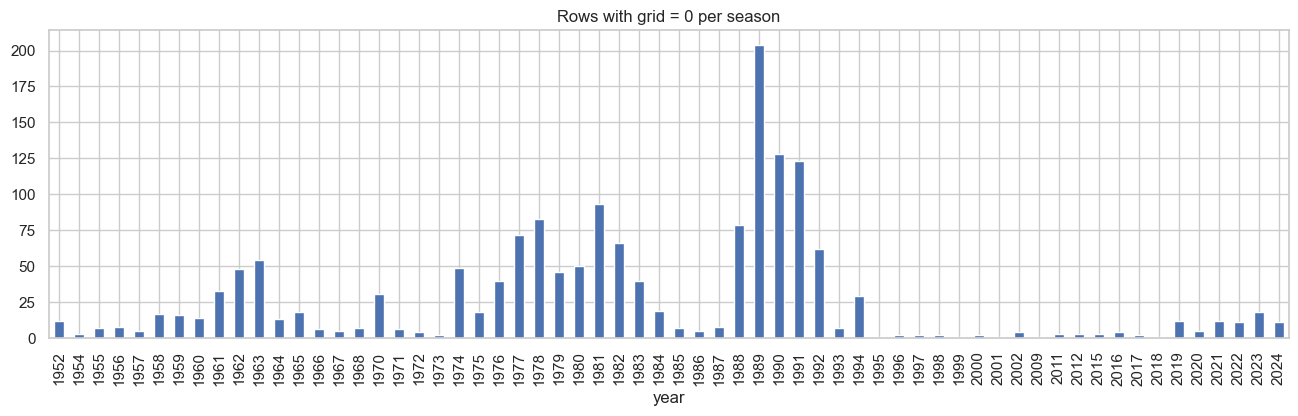

In [119]:
results[results['grid'] == 0].merge(races_clean[['raceId', 'year']], on='raceId')['year'] \
    .value_counts().sort_index().plot(kind='bar', figsize=(16, 4))
plt.title('Rows with grid = 0 per season')
plt.show()

**Note:** `grid` = 0 is concentrated in 1977–1983 and 1988–1992 (peak 1989, ~200 rows), the eras with more
entries than grid places, and is rare after 1995 (0–18 per season). This suggests `grid` = 0 mostly marks
drivers who did not start in the older eras, and pit-lane starts in the modern era (checked below).

### 2.2.7 Points in the 2014 Abu Dhabi Grand Prix
Checking whether the 50-point maximum comes from a race that awarded double points.

In [120]:
results[results['raceId'] == 918][['positionOrder', 'points']].sort_values('positionOrder').head(5)

,positionOrder,points
22514,1,50.0
22515,2,36.0
22516,3,30.0
22517,4,24.0
22518,5,20.0


**Note:** The top five in the 2014 Abu Dhabi GP scored 50, 36, 30, 24 and 20 points, exactly double the
normal 25, 18, 15, 12 and 10, so this race awarded double points. The 50-point maximum is real, not an
error. Points-based features would overweight this race; position-based features avoid this.

### 2.2.8 Rows with no official position
When `position` is `\N`, what does `positionText` record instead?

In [121]:
results[results['position'] == '\\N']['positionText'].value_counts()

positionText
R     8897
F     1368
W      336
N      190
D      151
E        9
11       1
14       1
Name: count, dtype: int64

In [122]:
results['positionText'].value_counts()

positionText
R     8897
F     1368
3     1135
4     1135
2     1133
5     1131
1     1128
6     1124
7     1104
8     1076
9     1038
10     978
11     902
12     800
13     713
14     606
15     528
16     432
17     336
W      336
18     223
N      190
D      151
19     141
20      72
21      34
22      19
E        9
23       8
24       3
25       1
26       1
27       1
28       1
29       1
30       1
31       1
32       1
33       1
Name: count, dtype: int64

**Note:** Every row with `position` = `\N` has a reason code in `positionText`: R (retired, 8,897),
F (failed to qualify, 1,368), W (withdrawn, 336), N (not classified, 190), D (disqualified, 151),
E (excluded, 9). Two rows have a number instead (11 and 14) and are inspected below.
Rows with F or W never started the race; since this is known at the prediction cutoff, they are
candidates for exclusion from the modeling table.

### 2.2.9 The two odd rows

In [123]:
results[(results['position'] == '\\N') & (results['positionText'].isin(['11', '14']))].merge(
    races_clean[['raceId', 'year', 'race_name']], on='raceId')

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,year,race_name
0,1149,71,18,16,3,8,\N,11,11,0.0,56,\N,\N,55,5,1:26.260,221.316,11,2005,Australian Grand Prix
1,1152,71,11,16,4,20,\N,14,14,0.0,55,\N,\N,36,16,1:27.877,217.244,12,2005,Australian Grand Prix


**Note:** The two rows with a numeric `positionText` but `position` = `\N` are both from the 2005 Australian GP
(drivers 18 and 11, 56 and 55 laps, `positionText` 11 and 14). `positionOrder` agrees with `positionText`
(11 and 14), so `position` appears to be missing by mistake for these two rows. This does not affect the
target, which is built from `positionOrder`.

### 2.2.10 Does grid = 0 match “failed to qualify”?

In [124]:
pd.crosstab(results['grid'] == 0, results['positionText'].isin(['F', 'W']),
            rownames=['grid = 0'], colnames=['F or W'])

F or W,False,True
grid = 0,,
False,24968,153
True,87,1551


**Note:** Of the 1,638 rows with `grid` = 0, 1,551 (~95%) are drivers coded F (failed to qualify) or
W (withdrawn). In this dataset `grid` = 0 therefore mostly means the driver did not start, not a pit-lane
start. Only 87 rows have `grid` = 0 for drivers who took part; these are the likely pit-lane starts.
Using `grid` = 0 as a number would wrongly rank these drivers ahead of pole position, so it needs handling
in cleaning.

### 2.2.11 Non-starters and grid = 0
Checks whether `grid` reliably tells us who started the race.

In [125]:
odd = results[(results['grid'] != 0) & (results['positionText'].isin(['F', 'W']))]
odd = odd.merge(races_clean[['raceId', 'year']], on='raceId')
pd.crosstab(odd['year'], odd['positionText'])

positionText,F,W
year,,
1950,0,3
1951,0,3
1952,0,2
1954,1,7
1955,0,3
1956,0,1
1957,0,1
1960,0,5
1964,1,1


20 are F - 133 are W

## Part A: The 133 W (withdrawn)
### Cell A1: did they race?

In [126]:
odd[odd['positionText'] == 'W']['laps'].value_counts()

laps
0     128
4       2
24      2
25      1
Name: count, dtype: int64

In [127]:
odd[(odd['positionText'] == 'W') & (odd['laps'] > 0)] \
    .merge(races_clean[['raceId', 'race_name']], on='raceId') \
    [['year', 'race_name', 'driverId', 'grid', 'laps', 'positionOrder', 'statusId']]

,year,race_name,driverId,grid,laps,positionOrder,statusId
0,1979,Dutch Grand Prix,182,9,4,20,54
1,1974,United States Grand Prix,319,26,25,21,54
2,1970,Spanish Grand Prix,345,5,4,14,54
3,1952,Swiss Grand Prix,475,9,24,12,54
4,1952,Swiss Grand Prix,651,12,24,13,54


In [128]:
status[status['statusId'] == 54]

,statusId,status
53,54,Withdrew


### Cell A2: the 2005 spike

In [129]:
odd[odd['year'] == 2005].merge(races_clean[['raceId', 'race_name']], on='raceId')['race_name'].value_counts()

race_name
United States Grand Prix    14
Bahrain Grand Prix           1
Name: count, dtype: int64

**Note (W drivers with a grid number, 133 rows):**
- **128 completed 0 laps:** they were given a grid slot from qualifying but withdrew before the start.
  14 of them come from a single race, the 2005 United States Grand Prix, where most of the field withdrew.
- **5 completed laps (4–25):** all have `statusId` 54 ("Withdrew" in the `status` table). They started the race
  and were withdrawn during it (e.g. two cars in the 1952 Swiss GP, both after 24 laps).

**Decision:** W therefore does not always mean "did not start", so the `started` flag treats W as a non-start
only when the driver completed 0 laps. The 5 drivers who raced are kept as starters (`podium` = 0).
The 128 who withdrew before the start had a grid slot at the prediction cutoff (after qualifying), so their
withdrawal was not yet known at prediction time. They are kept in the modelling table with `podium` = 0,
the same way as drivers who crash or break down during the race. Removing them would use information from
after the cutoff to decide which rows the model sees.

## Part B: The 20 F (failed to qualify)
### Cell B1: compare grid with qualifying position 

In [130]:
f_grid = results[(results['grid'] != 0) & (results['positionText'] == 'F')]
f_grid = f_grid.merge(races_clean[['raceId', 'year', 'race_name']], on='raceId')

quali_pos = qualifying[['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_position'})

f_grid.merge(quali_pos, on=['raceId', 'driverId'], how='left') \
    [['year', 'race_name', 'driverId', 'grid', 'quali_position', 'laps', 'positionOrder']]

,year,race_name,driverId,grid,quali_position,laps,positionOrder
0,1997,Australian Grand Prix,80,23,NaN,0,23
1,1997,Australian Grand Prix,73,24,NaN,0,24
2,1996,Australian Grand Prix,69,21,NaN,0,21
3,1996,Australian Grand Prix,85,22,NaN,0,22
4,1996,European Grand Prix,85,21,NaN,0,21
5,1996,European Grand Prix,69,22,NaN,0,22
6,1996,San Marino Grand Prix,85,22,22.0,0,22
7,1996,Monaco Grand Prix,85,22,22.0,0,22
8,1996,Spanish Grand Prix,69,21,NaN,0,21
9,1996,Spanish Grand Prix,85,22,NaN,0,22


In [131]:
print("F drivers:", len(f_grid), "| races:", f_grid['raceId'].nunique())

F drivers: 20 | races: 14


### Cell B2: does their grid continue right after the last starter?

In [132]:
f_races = f_grid['raceId'].unique()
field = results[results['raceId'].isin(f_races)][['raceId', 'driverId', 'grid', 'positionText', 'laps']]
field = field.merge(races_clean[['raceId', 'year', 'race_name']], on='raceId')
print(field.sort_values(['raceId', 'grid'])[['year', 'race_name', 'grid', 'positionText', 'laps']]
      .groupby(['year', 'race_name']).tail(5).to_string())

     year              race_name  grid positionText  laps
21   1997  Australian Grand Prix    20            W     0
16   1997  Australian Grand Prix    21            R     2
9    1997  Australian Grand Prix    22           10    54
22   1997  Australian Grand Prix    23            F     0
23   1997  Australian Grand Prix    24            F     0
32   1996  Australian Grand Prix    18            9    56
42   1996  Australian Grand Prix    19            R     1
33   1996  Australian Grand Prix    20           10    56
44   1996  Australian Grand Prix    21            F     0
45   1996  Australian Grand Prix    22            F     0
58   1996    European Grand Prix    18           13    65
57   1996    European Grand Prix    19           12    65
56   1996    European Grand Prix    20           11    65
66   1996    European Grand Prix    21            F     0
67   1996    European Grand Prix    22            F     0
76   1996  San Marino Grand Prix    18            9    61
86   1996  San

### 2.2.12 When did the 87 likely pit-lane starts happen?

In [133]:
pit_starts = results[(results['grid'] == 0) & (~results['positionText'].isin(['F', 'W']))]
pit_starts.merge(races_clean[['raceId', 'year']], on='raceId')['year'].value_counts().sort_index()

year
1981     1
1984     2
1987     1
1988     4
1989     2
1990     2
1992     1
1997     1
2015     1
2016     4
2017     2
2018     1
2019    12
2020     5
2021    11
2022    10
2023    16
2024    11
Name: count, dtype: int64

**Note:** Of the 87 rows with `grid` = 0 for drivers who took part, 73 (~84%) are from 2015–2024, consistent
with pit-lane starts in the modern era. The remaining 14 (1981–1997) are ambiguous. These drivers did start
the race, but from behind the whole grid, so `grid` = 0 must not be read as "ahead of pole".

In [134]:
pit_starts.merge(races_clean[['raceId', 'year', 'race_name']], on='raceId') \
    .query('year < 2000')[['year', 'race_name', 'driverId', 'positionText', 'positionOrder', 'laps', 'statusId']]

,year,race_name,driverId,positionText,positionOrder,laps,statusId
0,1997,Austrian Grand Prix,58,E,22,0,92
1,1992,German Grand Prix,135,E,32,0,96
2,1990,United States Grand Prix,112,D,27,0,2
3,1990,Mexican Grand Prix,90,D,27,0,2
4,1989,German Grand Prix,161,D,30,0,2
5,1989,Italian Grand Prix,131,D,27,0,2
6,1988,San Marino Grand Prix,78,E,27,0,96
7,1988,Monaco Grand Prix,131,E,31,0,96
8,1988,Mexican Grand Prix,131,E,31,0,96
9,1988,French Grand Prix,160,E,31,0,96


### 2.2.10 Cleaning
1. `\N` is replaced with NaN; `milliseconds`, `rank`, `fastestLap`, `fastestLapSpeed` are converted to numbers and
   `fastestLapTime` from text (e.g. `1:27.452`) to seconds (`fastestLapTime_s`).
2. **Duplicates:** for each (`raceId`, `driverId`) we keep the row with the best (lowest) `positionOrder`.
   This always works (`positionOrder` is never missing), matched the car with the most laps in all checked cases,
   and if any of a driver's cars finished on the podium, the driver was on the podium.
   Limitation: the kept row's `constructorId`/`grid` belong to that car.
   This is done before any joins, so later joins on (`raceId`, `driverId`) are one-to-one.
3. **Target:** `podium` = 1 if `positionOrder` ≤ 3, else 0.
4. **Flags:**
   - `started`: False if F, W with 0 laps, or `grid` = 0 with 0 laps.
   - `dns_known_at_cutoff`: True if F or `grid` = 0 with 0 laps; these rows are excluded from the modelling table in
     Section 3. W drivers who withdrew after getting a grid slot are kept (not yet known at the cutoff).
   - `pit_lane_start`: drivers who started with `grid` = 0.
5. **Dropped columns:** `resultId` (row ID, key verified) and `number` (car number, an identifier) by common sense;
   `position` because it equals `positionOrder` wherever both exist and is 41% `\N`;
   `time` because it holds the same information as `milliseconds` (missing in exactly the same rows) but as text
   mixing two formats. `fastestLapTime` is replaced by `fastestLapTime_s`.
6. **Kept as feature candidates** (decided in feature engineering with coverage and correlation checks):
   laps, milliseconds and the fastest-lap columns.
7. **Renamed** post-race columns to avoid clashing with same-named columns in other tables
   (e.g. `points` and `positionText` also exist in the standings tables with a different meaning):
   - `positionOrder` → `race_position_order` (the brief's target `positionOrder ≤ 3` is our `podium` column)
   - `positionText` → `race_position_text`
   - `points` → `race_points`, `laps` → `race_laps`, `milliseconds` → `race_ms`
   - fastest-lap columns → `fastest_lap_number`, `fastest_lap_rank`, `fastest_lap_time_s`, `fastest_lap_speed`
   Keys, `grid` and `statusId` keep their original names.

In [135]:
results_clean = results.copy()

# 1. Sentinels and types
results_clean = results_clean.replace('\\N', np.nan)
for col in ['milliseconds', 'rank', 'fastestLap', 'fastestLapSpeed']:
    results_clean[col] = pd.to_numeric(results_clean[col])

def lap_to_seconds(t):
    if pd.isna(t):
        return np.nan
    minutes, seconds = t.split(':')
    return int(minutes) * 60 + float(seconds)

results_clean['fastestLapTime_s'] = results_clean['fastestLapTime'].apply(lap_to_seconds)

# 2. Duplicates: keep the best positionOrder per driver per race
results_clean = results_clean.sort_values(['raceId', 'driverId', 'positionOrder']) \
                             .drop_duplicates(subset=['raceId', 'driverId'], keep='first')

# 3. Target
results_clean['podium'] = (results_clean['positionOrder'] <= 3).astype(int)

# 4. Flags
f_code   = results_clean['positionText'] == 'F'
w_0laps  = (results_clean['positionText'] == 'W') & (results_clean['laps'] == 0)
no_grid0 = (results_clean['grid'] == 0) & (results_clean['laps'] == 0)

results_clean['started'] = ~(f_code | w_0laps | no_grid0)
results_clean['dns_known_at_cutoff'] = f_code | no_grid0
results_clean['pit_lane_start'] = (results_clean['grid'] == 0) & results_clean['started']

# 5. Drop columns justified by common sense or evidence
results_clean = results_clean.drop(columns=['resultId', 'number', 'position', 'time', 'fastestLapTime'])

# 6. Rename post-race columns so they don't clash with other tables
results_clean = results_clean.rename(columns={
    'positionOrder': 'race_position_order',
    'positionText': 'race_position_text',
    'points': 'race_points',
    'laps': 'race_laps',
    'milliseconds': 'race_ms',
    'fastestLap': 'fastest_lap_number',
    'rank': 'fastest_lap_rank',
    'fastestLapTime_s': 'fastest_lap_time_s',
    'fastestLapSpeed': 'fastest_lap_speed'
})

### 2.2.11 After cleaning

In [136]:
results_clean.head()

,raceId,driverId,constructorId,grid,race_position_text,race_position_order,race_points,race_laps,race_ms,fastest_lap_number,fastest_lap_rank,fastest_lap_speed,statusId,fastest_lap_time_s,podium,started,dns_known_at_cutoff,pit_lane_start
7572,1,1,1,18,D,20,0.0,58,NaN,39.0,13.0,214.455,2,89.020,0,True,False,False
7562,1,2,2,9,10,10,0.0,58,5662869.0,48.0,5.0,216.245,1,88.283,0,True,False,False
7558,1,3,3,5,6,6,3.0,58,5661506.0,48.0,1.0,217.668,1,87.706,0,True,False,False
7557,1,4,4,10,5,5,4.0,58,5660663.0,53.0,9.0,215.199,1,88.712,0,True,False,False
7571,1,5,1,12,R,19,0.0,0,NaN,NaN,NaN,NaN,4,NaN,0,True,False,False


In [137]:
results_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26668 entries, 7572 to 26753
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   raceId               26668 non-null  int64  
 1   driverId             26668 non-null  int64  
 2   constructorId        26668 non-null  int64  
 3   grid                 26668 non-null  int64  
 4   race_position_text   26668 non-null  object 
 5   race_position_order  26668 non-null  int64  
 6   race_points          26668 non-null  float64
 7   race_laps            26668 non-null  int64  
 8   race_ms              7680 non-null   float64
 9   fastest_lap_number   8252 non-null   float64
 10  fastest_lap_rank     8510 non-null   float64
 11  fastest_lap_speed    8252 non-null   float64
 12  statusId             26668 non-null  int64  
 13  fastest_lap_time_s   8252 non-null   float64
 14  podium               26668 non-null  int64  
 15  started              26668 non-null  b

In [138]:
print("rows:", len(results_clean), "(expected 26,759 − 91 = 26,668)")
print("duplicate driver-race pairs:", results_clean.duplicated(subset=['raceId', 'driverId']).sum())
print("\\N left:", (results_clean == '\\N').sum().sum())

rows: 26668 (expected 26,759 − 91 = 26,668)
duplicate driver-race pairs: 0
\N left: 0


In [139]:
print(results_clean['started'].value_counts(), "\n")
print(results_clean['dns_known_at_cutoff'].value_counts(), "\n")
print("pit-lane starts:", results_clean['pit_lane_start'].sum())

started
True     24957
False     1711
Name: count, dtype: int64 

dns_known_at_cutoff
False    25085
True      1583
Name: count, dtype: int64 

pit-lane starts: 72


In [140]:
results_clean['podium'].value_counts(normalize=True)

podium
0    0.872694
1    0.127306
Name: proportion, dtype: float64

In [141]:
results_clean = results_clean.reset_index(drop=True)

In [142]:
results_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26668 entries, 0 to 26667
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   raceId               26668 non-null  int64  
 1   driverId             26668 non-null  int64  
 2   constructorId        26668 non-null  int64  
 3   grid                 26668 non-null  int64  
 4   race_position_text   26668 non-null  object 
 5   race_position_order  26668 non-null  int64  
 6   race_points          26668 non-null  float64
 7   race_laps            26668 non-null  int64  
 8   race_ms              7680 non-null   float64
 9   fastest_lap_number   8252 non-null   float64
 10  fastest_lap_rank     8510 non-null   float64
 11  fastest_lap_speed    8252 non-null   float64
 12  statusId             26668 non-null  int64  
 13  fastest_lap_time_s   8252 non-null   float64
 14  podium               26668 non-null  int64  
 15  started              26668 non-null 

**After cleaning (results):**
- 26,668 rows, no duplicate (`raceId`, `driverId`) pairs and no `\N` left: the required grain is met.
- `started` = False for 1,711 rows; `dns_known_at_cutoff` = True for 1,583. The difference (128) is exactly the
  W drivers who withdrew after receiving a grid slot, kept in the modelling table with `podium` = 0.
- 72 pit-lane starts: one of the 73 modern `grid` = 0 rows completed 0 laps and is treated as a non-starter
  (the lap-1 edge case noted in the limitations).
- `podium` = 1 for 12.7% of rows: the target is imbalanced, so accuracy would be misleading and PR-AUC/F1 are used.

In [143]:
circuits.head()

,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


In [144]:
circuits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB


In [145]:
circuits.describe()

,circuitId,lat,lng,alt
count,77.000000,77.000000,77.000000,77.000000
mean,39.883117,33.442925,1.076683,247.012987
std,23.001701,22.808866,65.516951,362.738469
min,1.000000,-37.849700,-118.189000,-7.000000
25%,20.000000,32.777400,-9.394170,18.000000
50%,40.000000,40.951700,3.930830,129.000000
75%,59.000000,46.958900,19.248600,332.000000
max,80.000000,57.265300,144.968000,2227.000000


In [146]:
circuits.isnull().sum()

circuitId     0
circuitRef    0
name          0
location      0
country       0
lat           0
lng           0
alt           0
url           0
dtype: int64

In [147]:
circuits.duplicated().sum()

np.int64(0)

In [148]:
(circuits == '\\N').sum()

circuitId     0
circuitRef    0
name          0
location      0
country       0
lat           0
lng           0
alt           0
url           0
dtype: int64

In [149]:
circuits['country'].value_counts()

country
USA              11
France            7
Spain             6
Italy             4
Portugal          4
UK                4
Germany           3
Belgium           3
Canada            3
Japan             3
Australia         2
Austria           2
Brazil            2
South Africa      2
Malaysia          1
Bahrain           1
Hungary           1
Turkey            1
Monaco            1
United States     1
China             1
Singapore         1
Argentina         1
Mexico            1
Korea             1
Netherlands       1
UAE               1
Sweden            1
Morocco           1
Switzerland       1
India             1
Russia            1
Azerbaijan        1
Saudi Arabia      1
Qatar             1
Name: count, dtype: int64

In [150]:
print("circuitId unique:", circuits['circuitId'].is_unique)
print("circuitId nulls:", circuits['circuitId'].isnull().sum())

circuitId unique: True
circuitId nulls: 0


**Observations (circuits):**
- 77 circuits, no missing values and no `\N` sentinels.
- `circuitId` is unique and non-null, so it is a valid primary key (IDs go up to 80, so some numbers are unused).
- `alt` minimum is -7 m: a circuit below sea level, a real value rather than an error.
- **Inconsistent category:** the US appears as both `USA` (11) and `United States` (1).
  This must be standardised in cleaning, otherwise Question 2 (home races) would treat them as different countries.
- Columns we will use: `circuitId` (join key), `name`, `country` (Question 2).
  `circuitRef`, `lat`, `lng`, `alt`, `url` are not needed.

**First Table** - Circuits (Clean)

Fix duplicated USA - United States

In [151]:
circuits_clean = circuits.copy()
circuits_clean['country'] = circuits_clean['country'].replace({'United States': 'USA'})

In [152]:
circuits_clean['country'].value_counts()

country
USA             12
France           7
Spain            6
Portugal         4
Italy            4
UK               4
Belgium          3
Canada           3
Germany          3
Japan            3
Austria          2
Australia        2
South Africa     2
Brazil           2
Malaysia         1
Turkey           1
Monaco           1
Bahrain          1
China            1
Singapore        1
Hungary          1
Argentina        1
Mexico           1
Korea            1
Netherlands      1
UAE              1
Sweden           1
Morocco          1
Switzerland      1
India            1
Russia           1
Azerbaijan       1
Saudi Arabia     1
Qatar            1
Name: count, dtype: int64

## Drop Url Column in Circuits table

Justification:  `url`: Wikipedia link, contains no information about races.

In [153]:
circuits_clean = circuits_clean.drop(columns=['url'])

**Second Table** - Constructor_Results

In [154]:
constructor_results.head()

,constructorResultsId,raceId,constructorId,race_specific_contsructor_points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN


In [155]:
constructor_results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   constructorResultsId              12625 non-null  int64  
 1   raceId                            12625 non-null  int64  
 2   constructorId                     12625 non-null  int64  
 3   race_specific_contsructor_points  12625 non-null  float64
 4   status                            17 non-null     object 
dtypes: float64(1), int64(3), object(1)
memory usage: 493.3+ KB


In [156]:
constructor_results.isnull().sum()

constructorResultsId                    0
raceId                                  0
constructorId                           0
race_specific_contsructor_points        0
status                              12608
dtype: int64

In [157]:
(constructor_results == '\\N').sum()

constructorResultsId                0
raceId                              0
constructorId                       0
race_specific_contsructor_points    0
status                              0
dtype: int64

In [158]:
constructors['nationality'].value_counts()

KeyError: 'nationality'

In [ ]:
print("constructorResultsId unique:", constructor_results['constructorResultsId'].is_unique)
print("constructorResultsId nulls:", constructor_results['constructorResultsId'].isnull().sum())

In [ ]:
constructor_results['points'].describe()

In [ ]:
constructor_results[constructor_results['status'] != '\\N']

In [ ]:
d_rows = constructor_results[constructor_results['status'] == 'D']
d_rows

In [ ]:
constructors[constructors['constructorId'].isin(d_rows['constructorId'])]

**Observations (constructor_results):**
- 12,625 rows, one per constructor per race.
- `isnull()` reports no missing values, but `status` contains 12,608 `\N` placeholders (99.9%).
  This shows `\N` sentinels hide missing data from `.isnull()`; they must be converted to real NaN in cleaning.
- `status` is almost entirely empty, so it will be dropped.
- `points` is post-race information. Constructor form will be built from `constructor_standings` instead,
  so this table is likely not needed for modelling.

## 3rd Table Constructor_Standings

In [ ]:
constructor_standings.head()

In [ ]:
constructor_standings.info()

In [ ]:
constructor_standings.describe()

In [ ]:
constructor_standings.isnull().sum()

In [ ]:
(constructor_standings == '\\N').sum()

In [ ]:
print("constructorStandingsId unique:", constructor_standings['constructorStandingsId'].is_unique)
print("constructorStandingsId nulls:", constructor_standings['constructorStandingsId'].isnull().sum())

In [ ]:
constructor_standings.duplicated(subset=['raceId', 'constructorId']).sum()

## 4th Table - Constructors

In [ ]:
constructors.head()

In [ ]:
constructors.info()

In [ ]:
(constructors == '\\N').sum()

In [ ]:
constructors['nationality'].value_counts()

In [ ]:
print("constructorId unique:", constructors['constructorId'].is_unique)
print("constructorId nulls:", constructors['constructorId'].isnull().sum())

In [ ]:
constructors[constructors['name'].duplicated(keep=False)]

In [ ]:
constructors[constructors['constructorRef'].duplicated(keep=False)]